Importing dataset

In [ ]:
import pandas as pd

splits = {'train': 'split/train-00000-of-00001.parquet', 'validation': 'split/validation-00000-of-00001.parquet', 'test': 'split/test-00000-of-00001.parquet'}
df = pd.read_parquet("hf://datasets/dair-ai/emotion/" + splits["train"])
df.head()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


,text,label
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,3
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,3


downloading missing libraries

In [ ]:

!pip install datasets transformers torch scikit-learn matplotlib seaborn bitsandbytes accelerate sentencepiece

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 11.8 MB/s eta 0:00:00


Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time #to track time for epochs
import torch #pytorch
import torch.nn as nn #layers , loss , crossentropy
from torch.utils.data import Dataset, DataLoader #wrapper to slice data into patches
from collections import Counter #to count class distributions
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup) #autotokenizer to get correct vocab , autoModel to download pre trained model
from torch.optim import AdamW #version of adam opt that handles weight decay

In [ ]:
# Check GPU availability ashan mnfdalsh ad kda
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [ ]:
# Label mapping for the 6 emotions
LABEL_NAMES = ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
NUM_CLASSES = 6

Part 1 — Data Preprocessing & Exploration

downloaded bs n make sure tany w n add kol part of data into a variable

In [ ]:
#splits as required in description
splits = {
    'train':      'split/train-00000-of-00001.parquet',
    'validation': 'split/validation-00000-of-00001.parquet',
    'test':       'split/test-00000-of-00001.parquet'
}

In [ ]:
#distributing w printing
train_df = pd.read_parquet("hf://datasets/dair-ai/emotion/" + splits["train"])
val_df   = pd.read_parquet("hf://datasets/dair-ai/emotion/" + splits["validation"])
test_df  = pd.read_parquet("hf://datasets/dair-ai/emotion/" + splits["test"])

print("Train shape:", train_df.shape)
print("Val shape:  ", val_df.shape)
print("Test shape: ", test_df.shape)
print("\nSample rows:")
print(train_df.head())
print("\nColumns:", train_df.columns.tolist())
print("\nData types:\n", train_df.dtypes)

Train shape: (16000, 2)
Val shape:   (2000, 2)
Test shape:  (2000, 2)

Sample rows:
                                                text  label
0                            i didnt feel humiliated      0
1  i can go from feeling so hopeless to so damned...      0
2   im grabbing a minute to post i feel greedy wrong      3
3  i am ever feeling nostalgic about the fireplac...      2
4                               i am feeling grouchy      3

Columns: ['text', 'label']

Data types:
 text     object
label     int64
dtype: object


In [ ]:
#statistics for class distribution for each split
print("=== CLASS DISTRIBUTION ===\n")
for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(f"--- {name} ---")
    counts = df['label'].value_counts().sort_index()
    for idx, cnt in counts.items():
        print(f"  {LABEL_NAMES[idx]:10s} (label {idx}): {cnt}")
    print()

=== CLASS DISTRIBUTION ===

--- Train ---
  sadness    (label 0): 4666
  joy        (label 1): 5362
  love       (label 2): 1304
  anger      (label 3): 2159
  fear       (label 4): 1937
  surprise   (label 5): 572

--- Val ---
  sadness    (label 0): 550
  joy        (label 1): 704
  love       (label 2): 178
  anger      (label 3): 275
  fear       (label 4): 212
  surprise   (label 5): 81

--- Test ---
  sadness    (label 0): 581
  joy        (label 1): 695
  love       (label 2): 159
  anger      (label 3): 275
  fear       (label 4): 224
  surprise   (label 5): 66



In [ ]:
# sentences length stat
for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    lengths = df['text'].str.split().apply(len)  # word-level tokens
    print(f"[{name}] Length stats → mean: {lengths.mean():.1f}, "
          f"median: {lengths.median()}, max: {lengths.max()}, min: {lengths.min()}")

[Train] Length stats → mean: 19.2, median: 17.0, max: 66, min: 2
[Val] Length stats → mean: 18.9, median: 17.0, max: 61, min: 2
[Test] Length stats → mean: 19.2, median: 17.0, max: 61, min: 3


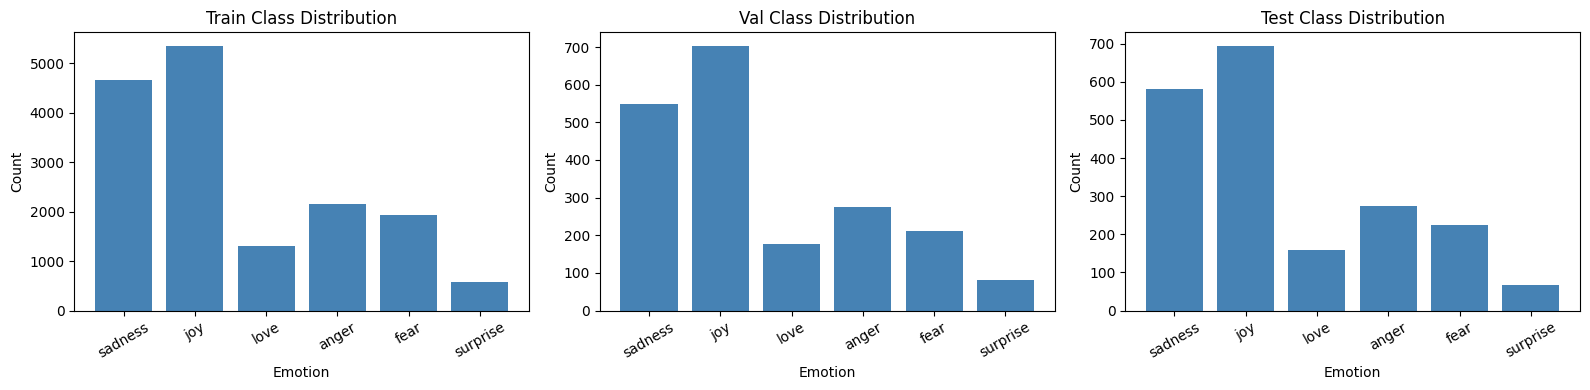

In [ ]:
#check for balance
#bar chart
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, df) in zip(axes, [("Train", train_df), ("Val", val_df), ("Test", test_df)]):
    counts = df['label'].value_counts().sort_index()
    ax.bar([LABEL_NAMES[i] for i in counts.index], counts.values, color='steelblue')
    ax.set_title(f"{name} Class Distribution")
    ax.set_xlabel("Emotion")
    ax.set_ylabel("Count")
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()

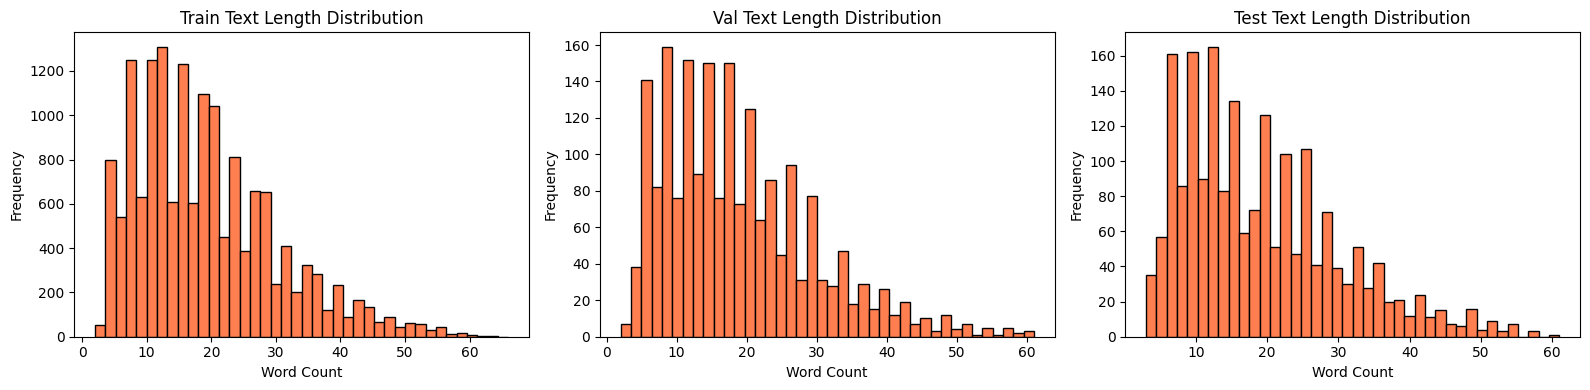

In [ ]:
# plot el sentences bardo
#histogram
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, df) in zip(axes, [("Train", train_df), ("Val", val_df), ("Test", test_df)]):
    lengths = df['text'].str.split().apply(len)
    ax.hist(lengths, bins=40, color='coral', edgecolor='black')
    ax.set_title(f"{name} Text Length Distribution")
    ax.set_xlabel("Word Count")
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.savefig("length_distribution.png", dpi=150)
plt.show()

In [ ]:
#tokenizer for the RNN
# will make it with lowercase however i will keep the punctuation as it matters for detecting the meaning
# Max length = 50 words , it will cover almost 90 to 95% of sample
MAX_LEN_RNN = 50
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

def build_vocab(texts, min_freq=2):
    """Build a word-to-index vocabulary from a list of texts."""
    counter = Counter()
    for text in texts:
        tokens = text.lower().split()
        counter.update(tokens)
    vocab = {PAD_TOKEN: 0, UNK_TOKEN: 1}
    for word, freq in counter.items():
        if freq >= min_freq:
            vocab[word] = len(vocab)
    return vocab

vocab = build_vocab(train_df['text'].tolist())
print(f"Vocabulary size: {len(vocab)}")

def text_to_indices(text, vocab, max_len):
    """Convert a raw text string to a padded list of indices."""
    tokens = text.lower().split()[:max_len]
    indices = [vocab.get(t, vocab[UNK_TOKEN]) for t in tokens]
    # Pad or truncate to max_len
    indices += [vocab[PAD_TOKEN]] * (max_len - len(indices))
    return indices

Vocabulary size: 7401


In [ ]:
#another tokenizer for transformer
TRANSFORMER_MODEL = "distilbert-base-uncased"
MAX_LEN_TRANSFORMER = 64  # tweets are short; 64 is sufficient

bert_tokenizer = AutoTokenizer.from_pretrained(TRANSFORMER_MODEL)

# Quick check
sample = train_df['text'].iloc[0]
encoded = bert_tokenizer(sample, truncation=True, max_length=MAX_LEN_TRANSFORMER,
                         padding='max_length', return_tensors='pt')
print("Sample text:", sample)
print("Token IDs shape:", encoded['input_ids'].shape)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Sample text: i didnt feel humiliated
Token IDs shape: torch.Size([1, 64])


i made the sentences lowercased for RNN tokenizer while i didnt
for BERT as it handles it on its own


min_freq=2 in vocab: removes misspelled words that add noise

Part 2 — Baseline: From-Scratch RNN Classifier


In [ ]:
#pytorch data set
class RNNEmotionDataset(Dataset):
    def __init__(self, df, vocab, max_len):
        self.labels = df['label'].tolist()
        self.sequences = [
            text_to_indices(text, vocab, max_len)
            for text in df['text'].tolist()
        ]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.sequences[idx], dtype=torch.long),
            torch.tensor(self.labels[idx],    dtype=torch.long)
        )

train_rnn_ds = RNNEmotionDataset(train_df, vocab, MAX_LEN_RNN)
val_rnn_ds   = RNNEmotionDataset(val_df,   vocab, MAX_LEN_RNN)
test_rnn_ds  = RNNEmotionDataset(test_df,  vocab, MAX_LEN_RNN)

BATCH_SIZE = 64
train_rnn_dl = DataLoader(train_rnn_ds, batch_size=BATCH_SIZE, shuffle=True)
val_rnn_dl   = DataLoader(val_rnn_ds,   batch_size=BATCH_SIZE)
test_rnn_dl  = DataLoader(test_rnn_ds,  batch_size=BATCH_SIZE)

will use GRU instead of lstm as it is faster to train and performs better on smaller datasets

In [ ]:
#GRU
class GRUClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers, num_classes, dropout=0.3):
        super().__init__()
        # Embedding: maps word indices to dense vectors
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        # GRU: processes the sequence
        self.gru = nn.GRU(embed_dim, hidden_dim, num_layers=num_layers,
                          batch_first=True, dropout=dropout if num_layers > 1 else 0,
                          bidirectional=True)
        # Classifier head: takes last hidden state → class logits
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)  # *2 for bidirectional

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))   # (batch, seq, embed)
        output, hidden = self.gru(embedded)           # hidden: (2*layers, batch, hidden)
        # Concatenate final forward and backward hidden states
        hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.fc(self.dropout(hidden))          # (batch, num_classes)

# Hyperparameters
EMBED_DIM  = 128
HIDDEN_DIM = 256
NUM_LAYERS = 2
DROPOUT    = 0.3
LR_RNN     = 1e-3
RNN_EPOCHS = 10

rnn_model = GRUClassifier(len(vocab), EMBED_DIM, HIDDEN_DIM, NUM_LAYERS, NUM_CLASSES, DROPOUT).to(device)
print(rnn_model)
total_params = sum(p.numel() for p in rnn_model.parameters() if p.requires_grad)
print(f"\nTotal trainable parameters: {total_params:,}")

GRUClassifier(
  (embedding): Embedding(7401, 128, padding_idx=0)
  (gru): GRU(128, 256, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=512, out_features=6, bias=True)
)

Total trainable parameters: 2,726,022


In [ ]:
#training
optimizer_rnn = torch.optim.Adam(rnn_model.parameters(), lr=LR_RNN)
criterion = nn.CrossEntropyLoss()

def train_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct = 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(X)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * X.size(0)
        correct += (logits.argmax(1) == y).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

def eval_epoch(model, loader):
    model.eval()
    total_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            loss = criterion(logits, y)
            total_loss += loss.item() * X.size(0)
            correct += (logits.argmax(1) == y).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

rnn_train_losses, rnn_val_losses = [], []
rnn_train_accs,   rnn_val_accs   = [], []

print("Training RNN...")
rnn_start_time = time.time()

for epoch in range(1, RNN_EPOCHS + 1):
    tr_loss, tr_acc = train_epoch(rnn_model, train_rnn_dl, optimizer_rnn)
    vl_loss, vl_acc = eval_epoch(rnn_model, val_rnn_dl)
    rnn_train_losses.append(tr_loss)
    rnn_val_losses.append(vl_loss)
    rnn_train_accs.append(tr_acc)
    rnn_val_accs.append(vl_acc)
    print(f"Epoch {epoch:2d} | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} "
          f"| Val Loss: {vl_loss:.4f} Acc: {vl_acc:.4f}")

rnn_train_time = time.time() - rnn_start_time
print(f"\nTotal RNN training time: {rnn_train_time:.1f}s")

Training RNN...
Epoch  1 | Train Loss: 1.4679 Acc: 0.4155 | Val Loss: 1.0394 Acc: 0.6270
Epoch  2 | Train Loss: 0.7917 Acc: 0.7140 | Val Loss: 0.3815 Acc: 0.8640
Epoch  3 | Train Loss: 0.4162 Acc: 0.8484 | Val Loss: 0.2546 Acc: 0.9060
Epoch  4 | Train Loss: 0.2740 Acc: 0.8958 | Val Loss: 0.2082 Acc: 0.9140
Epoch  5 | Train Loss: 0.2066 Acc: 0.9163 | Val Loss: 0.1958 Acc: 0.9220
Epoch  6 | Train Loss: 0.1659 Acc: 0.9326 | Val Loss: 0.1776 Acc: 0.9230
Epoch  7 | Train Loss: 0.1414 Acc: 0.9417 | Val Loss: 0.1867 Acc: 0.9225
Epoch  8 | Train Loss: 0.1220 Acc: 0.9493 | Val Loss: 0.1775 Acc: 0.9295
Epoch  9 | Train Loss: 0.1072 Acc: 0.9569 | Val Loss: 0.1827 Acc: 0.9285
Epoch 10 | Train Loss: 0.0938 Acc: 0.9620 | Val Loss: 0.1896 Acc: 0.9270

Total RNN training time: 56.5s


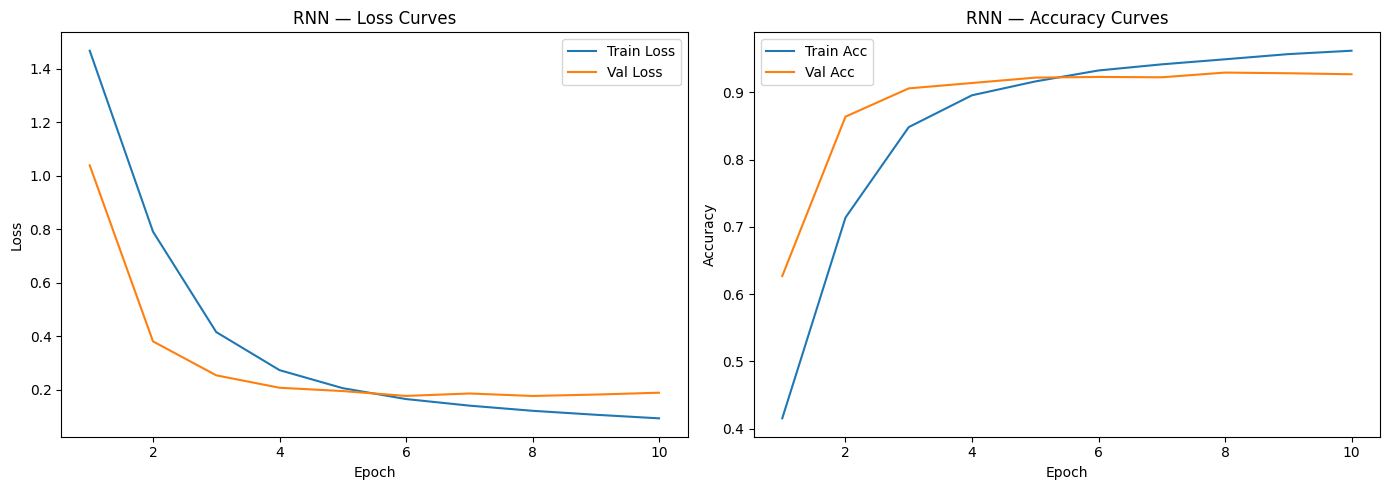

In [ ]:
#plotting loss curves to check for overfitting or underfitting easily
epochs_range = range(1, RNN_EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_range, rnn_train_losses, label='Train Loss')
ax1.plot(epochs_range, rnn_val_losses,   label='Val Loss')
ax1.set_title("RNN — Loss Curves")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.legend()

ax2.plot(epochs_range, rnn_train_accs, label='Train Acc')
ax2.plot(epochs_range, rnn_val_accs,   label='Val Acc')
ax2.set_title("RNN — Accuracy Curves")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy"); ax2.legend()

plt.tight_layout()
plt.savefig("rnn_curves.png", dpi=150)
plt.show()

after Epoch 7 the model is beginning to memorize the training data rather than learning

by Epoch 6 the validation accuracy hits a ceiling at approximately 92–93%. Even as the training accuracy keeps climbing toward 95%+, the validation accuracy remains flat.

In [ ]:
#RNN eval on test split
def get_predictions(model, loader):
    """Returns all true labels and predicted labels for a dataset."""
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for X, y in loader:
            X = X.to(device)
            preds = model(X).argmax(1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(y.numpy())
    return np.array(all_labels), np.array(all_preds)

# Inference time
infer_start = time.time()
rnn_true, rnn_pred = get_predictions(rnn_model, test_rnn_dl)
rnn_infer_time = time.time() - infer_start

print("=== RNN Test Results ===")
print(f"Accuracy:  {accuracy_score(rnn_true, rnn_pred):.4f}")
print(f"Macro F1:  {f1_score(rnn_true, rnn_pred, average='macro'):.4f}")
print(f"Train time: {rnn_train_time:.1f}s | Inference time: {rnn_infer_time:.3f}s")
print("\nPer-class report:")
print(classification_report(rnn_true, rnn_pred, target_names=LABEL_NAMES))

=== RNN Test Results ===
Accuracy:  0.9145
Macro F1:  0.8708
Train time: 56.5s | Inference time: 0.159s

Per-class report:
              precision    recall  f1-score   support

     sadness       0.96      0.97      0.96       581
         joy       0.96      0.90      0.93       695
        love       0.73      0.92      0.82       159
       anger       0.96      0.90      0.93       275
        fear       0.87      0.87      0.87       224
    surprise       0.66      0.79      0.72        66

    accuracy                           0.91      2000
   macro avg       0.86      0.89      0.87      2000
weighted avg       0.92      0.91      0.92      2000



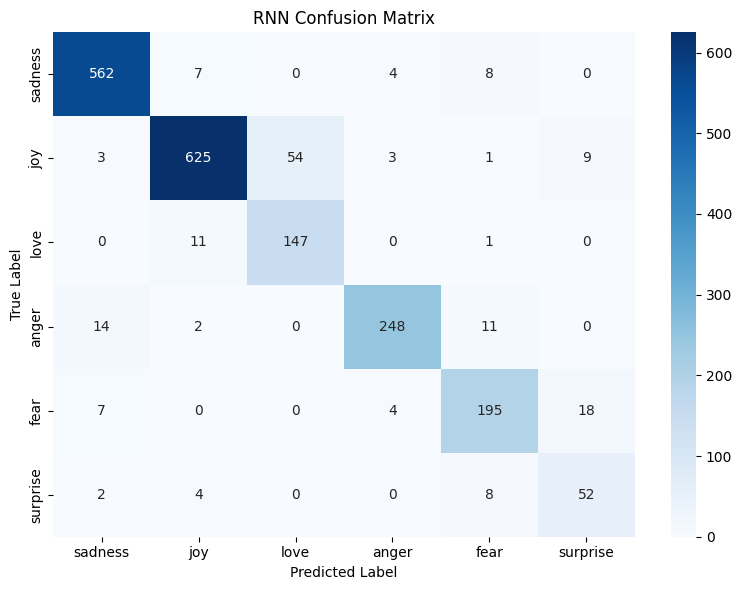

In [ ]:
#building confusion matrix for RNN
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
    plt.title(title)
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.tight_layout()
    plt.savefig(f"{title.replace(' ', '_')}.png", dpi=150)
    plt.show()

plot_confusion_matrix(rnn_true, rnn_pred, "RNN Confusion Matrix")

Part 3 — Transfer Learning: Fine-Tuned Transformer


using distilbert as it is a smaller, faster, and more lightweight

In [ ]:
#data set and tokenizing for this transformer
class TransformerEmotionDataset(Dataset):
    def __init__(self, df, tokenizer, max_len):
        self.labels = df['label'].tolist()
        # Tokenize all texts upfront
        self.encodings = tokenizer(
            df['text'].tolist(),
            truncation=True,
            padding='max_length',
            max_length=max_len,
            return_tensors='pt'
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            'input_ids':      self.encodings['input_ids'][idx],
            'attention_mask': self.encodings['attention_mask'][idx],
            'labels':         torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_bert_ds = TransformerEmotionDataset(train_df, bert_tokenizer, MAX_LEN_TRANSFORMER)
val_bert_ds   = TransformerEmotionDataset(val_df,   bert_tokenizer, MAX_LEN_TRANSFORMER)
test_bert_ds  = TransformerEmotionDataset(test_df,  bert_tokenizer, MAX_LEN_TRANSFORMER)

BERT_BATCH = 32
train_bert_dl = DataLoader(train_bert_ds, batch_size=BERT_BATCH, shuffle=True)
val_bert_dl   = DataLoader(val_bert_ds,   batch_size=BERT_BATCH)
test_bert_dl  = DataLoader(test_bert_ds,  batch_size=BERT_BATCH)

In [ ]:
#loading distilbert
#with the required automodel classification
bert_model = AutoModelForSequenceClassification.from_pretrained(
    TRANSFORMER_MODEL,
    num_labels=NUM_CLASSES
).to(device)

total_bert_params = sum(p.numel() for p in bert_model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {total_bert_params:,}")


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total trainable parameters: 66,958,086


In [ ]:
#tuning loop
BERT_EPOCHS = 3
LR_BERT     = 3e-5

optimizer_bert = AdamW(bert_model.parameters(), lr=LR_BERT, weight_decay=0.01)

# Linear warmup scheduler (standard for transformer fine-tuning)
total_steps   = len(train_bert_dl) * BERT_EPOCHS
warmup_steps  = total_steps // 10
scheduler     = get_linear_schedule_with_warmup(
    optimizer_bert, num_warmup_steps=warmup_steps, num_training_steps=total_steps
)

bert_train_losses, bert_val_losses = [], []
bert_train_accs,   bert_val_accs   = [], []

print("Fine-tuning DistilBERT...")
bert_start_time = time.time()

for epoch in range(1, BERT_EPOCHS + 1):
    # --- Training ---
    bert_model.train()
    tr_loss, tr_correct = 0, 0
    for batch in train_bert_dl:
        input_ids = batch['input_ids'].to(device)
        attn_mask = batch['attention_mask'].to(device)
        labels    = batch['labels'].to(device)

        optimizer_bert.zero_grad()
        outputs = bert_model(input_ids=input_ids, attention_mask=attn_mask, labels=labels)
        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(bert_model.parameters(), 1.0)  # gradient clipping
        optimizer_bert.step()
        scheduler.step()

        tr_loss    += loss.item() * input_ids.size(0)
        tr_correct += (outputs.logits.argmax(1) == labels).sum().item()

    # --- Validation ---
    bert_model.eval()
    vl_loss, vl_correct = 0, 0
    with torch.no_grad():
        for batch in val_bert_dl:
            input_ids = batch['input_ids'].to(device)
            attn_mask = batch['attention_mask'].to(device)
            labels    = batch['labels'].to(device)
            outputs   = bert_model(input_ids=input_ids, attention_mask=attn_mask, labels=labels)
            vl_loss    += outputs.loss.item() * input_ids.size(0)
            vl_correct += (outputs.logits.argmax(1) == labels).sum().item()

    n_tr = len(train_bert_ds); n_vl = len(val_bert_ds)
    bert_train_losses.append(tr_loss / n_tr)
    bert_val_losses.append(vl_loss / n_vl)
    bert_train_accs.append(tr_correct / n_tr)
    bert_val_accs.append(vl_correct / n_vl)
    print(f"Epoch {epoch} | Train Loss: {tr_loss/n_tr:.4f} Acc: {tr_correct/n_tr:.4f} "
          f"| Val Loss: {vl_loss/n_vl:.4f} Acc: {vl_correct/n_vl:.4f}")

bert_train_time = time.time() - bert_start_time
print(f"\nTotal BERT training time: {bert_train_time:.1f}s")

Fine-tuning DistilBERT...
Epoch 1 | Train Loss: 0.6777 Acc: 0.7574 | Val Loss: 0.1787 Acc: 0.9330
Epoch 2 | Train Loss: 0.1513 Acc: 0.9388 | Val Loss: 0.1476 Acc: 0.9420
Epoch 3 | Train Loss: 0.0935 Acc: 0.9575 | Val Loss: 0.1341 Acc: 0.9415

Total BERT training time: 276.5s


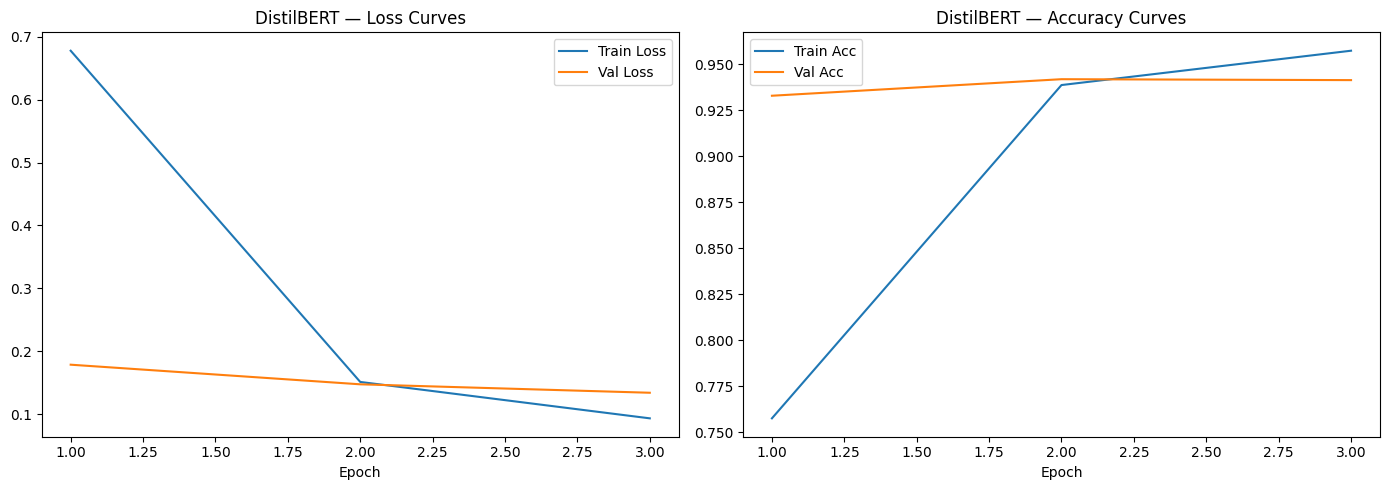

In [ ]:
#plot loss
epochs_range_bert = range(1, BERT_EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(epochs_range_bert, bert_train_losses, label='Train Loss')
ax1.plot(epochs_range_bert, bert_val_losses,   label='Val Loss')
ax1.set_title("DistilBERT — Loss Curves"); ax1.set_xlabel("Epoch"); ax1.legend()

ax2.plot(epochs_range_bert, bert_train_accs, label='Train Acc')
ax2.plot(epochs_range_bert, bert_val_accs,   label='Val Acc')
ax2.set_title("DistilBERT — Accuracy Curves"); ax2.set_xlabel("Epoch"); ax2.legend()
plt.tight_layout(); plt.savefig("bert_curves.png", dpi=150); plt.show()

by epoch 2 the model was rapidly adapted and learned and this is normal for fine tuning
by epoch 3 the validation accuracy has flattened out at ~93.5%.

=== DistilBERT Test Results ===
Accuracy:  0.9295
Macro F1:  0.8854
Train time: 276.5s | Inference time: 3.692s

Per-class report:
              precision    recall  f1-score   support

     sadness       0.97      0.96      0.97       581
         joy       0.95      0.94      0.95       695
        love       0.82      0.86      0.84       159
       anger       0.90      0.96      0.93       275
        fear       0.90      0.89      0.90       224
    surprise       0.77      0.70      0.73        66

    accuracy                           0.93      2000
   macro avg       0.89      0.89      0.89      2000
weighted avg       0.93      0.93      0.93      2000



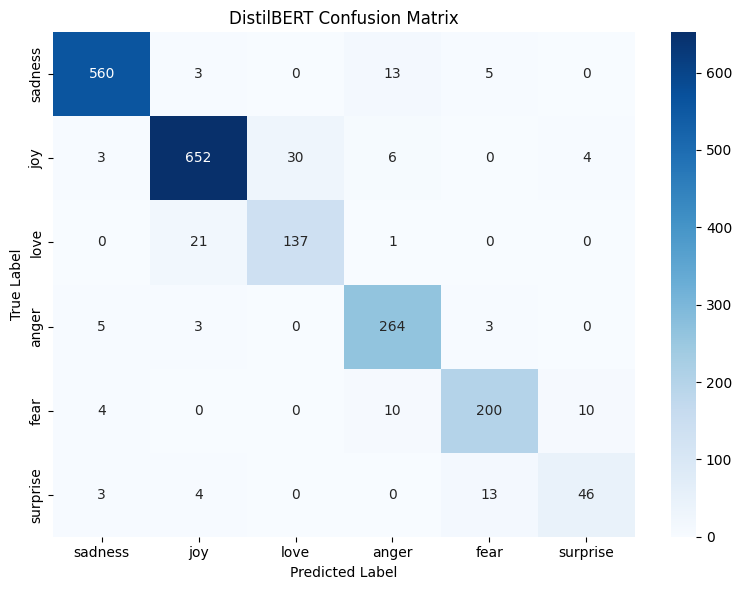

In [ ]:
#evalutaing distilbert on test split
def get_bert_predictions(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attn_mask = batch['attention_mask'].to(device)
            labels    = batch['labels']
            logits    = model(input_ids=input_ids, attention_mask=attn_mask).logits
            preds     = logits.argmax(1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())
    return np.array(all_labels), np.array(all_preds)

infer_start = time.time()
bert_true, bert_pred = get_bert_predictions(bert_model, test_bert_dl)
bert_infer_time = time.time() - infer_start

print("=== DistilBERT Test Results ===")
print(f"Accuracy:  {accuracy_score(bert_true, bert_pred):.4f}")
print(f"Macro F1:  {f1_score(bert_true, bert_pred, average='macro'):.4f}")
print(f"Train time: {bert_train_time:.1f}s | Inference time: {bert_infer_time:.3f}s")
print("\nPer-class report:")
print(classification_report(bert_true, bert_pred, target_names=LABEL_NAMES))

plot_confusion_matrix(bert_true, bert_pred, "DistilBERT Confusion Matrix")

since distilbert is pre trained then we dont have to train it from scratch on emotions we just need to tell him which words are signals for which emotions  however it updates ~66M parameters. It was pretrained using masked language modeling (MLM) on BooksCorpus + Wikipedia
 predicting randomly masked tokens forces it to learn grammar and  context

Part 4 — LLM Prompting (No Training)

In [ ]:

from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, pipeline,GenerationConfig

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16
)


LLM_MODEL = "microsoft/Phi-3-mini-4k-instruct"

llm_tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL)
llm_model     = AutoModelForCausalLM.from_pretrained(
    LLM_MODEL,
    quantization_config=quant_config,
    device_map="auto",
)

llm_pipe = pipeline(
    "text-generation",
    model=llm_model,
    tokenizer=llm_tokenizer,
    return_full_text=False,
    max_new_tokens=15,
    do_sample=False,
    repetition_penalty=1.1,
)
print("Pipeline ready.")

config.json:   0%|          | 0.00/967 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/306 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/599 [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Passing `generation_config` together with generation-related arguments=({'repetition_penalty', 'do_sample', 'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


Pipeline ready.


***explaination of prompting techniques as teached in RM course ***

Zero-Shot :No context/examples ,Simple & common tasks
Few-Shot: 2–5 examples ,Specific formats or nuances
CoTLogic: Reasoning steps, Math, logic, and multi-step problems



In [ ]:

def format_chat_prompt(user_message):
    messages = [
        {
            "role": "system",
            "content": (
                "You are an emotion classifier. "
                "You must respond with ONLY a single word — nothing else. "
                "No sentences, no explanation, no punctuation. "
                "The word must be one of: sadness, joy, love, anger, fear, surprise."
            )
        },
        {"role": "user", "content": user_message}
    ]
    return llm_tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )

EMOTION_CLASSES = "sadness, joy, love, anger, fear, surprise"

def zero_shot_prompt(text):
    user_msg = (
        f"Text: {text}\n\n"
        f"Emotion (one word only):"
    )
    return format_chat_prompt(user_msg)

def few_shot_prompt(text, examples):
    user_msg = (
        f"Examples (Text → Emotion):\n"
        f"{examples}\n"
        f"Text: {text}\n"
        f"Emotion:"
    )
    return format_chat_prompt(user_msg)

def cot_prompt(text):
    user_msg = (
        f"Text: {text}\n\n"
        f"Think briefly:\n"
        f"- Key emotional words: ?\n"
        f"- Overall tone: ?\n"
        f"Final emotion:"
    )
    return format_chat_prompt(user_msg)

In [ ]:

sample_texts = test_df['text'].iloc[:3].tolist()
sample_labels = test_df['label'].iloc[:3].tolist()

print("=== RAW MODEL OUTPUTS ===\n")
for i, (text, label) in enumerate(zip(sample_texts, sample_labels)):
    prompt = zero_shot_prompt(text)
    raw = llm_pipe(prompt)[0]['generated_text']
    print(f"--- Example {i+1} ---")
    print(f"True label : {LABEL_NAMES[label]}")
    print(f"repr(raw)  : {repr(raw)}")
    print(f"raw        : {raw}")
    print()

Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


=== RAW MODEL OUTPUTS ===



Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


--- Example 1 ---
True label : sadness
repr(raw)  : ' Sadness'
raw        :  Sadness



Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


--- Example 2 ---
True label : sadness
repr(raw)  : ' Sadness'
raw        :  Sadness

--- Example 3 ---
True label : sadness
repr(raw)  : ' Sadness'
raw        :  Sadness



In [ ]:

import re

LABEL_ALIASES = {
    "sad": "sadness", "sadness": "sadness",
    "happy": "joy", "happiness": "joy", "joyful": "joy", "joy": "joy",
    "love": "love", "loving": "love", "loved": "love",
    "angry": "anger", "anger": "anger", "furious": "anger", "mad": "anger",
    "afraid": "fear", "scared": "fear", "fear": "fear", "fearful": "fear",
    "surprise": "surprise", "surprised": "surprise",
    "shock": "surprise", "shocked": "surprise",
}

def extract_label(raw_output):
    text = raw_output.lower().strip()
    text = re.sub(r'[^\w\s]', ' ', text)
    words = text.split()
    for word in words:
        if word in LABEL_NAMES:
            return word
    for word in words:
        if word in LABEL_ALIASES:
            return LABEL_ALIASES[word]
    match = re.search(r'final emotion[:\s]+(\w+)', text)
    if match:
        candidate = match.group(1)
        if candidate in LABEL_ALIASES:
            return LABEL_ALIASES[candidate]
    for label in LABEL_NAMES:
        if label in text:
            return label
    return "unknown"

def run_llm_evaluation(prompt_fn, df, sample_n=None, debug=False, cot=False):
    data = df.sample(sample_n, random_state=42) if sample_n else df
    true_labels, pred_labels = [], []
    unknown_count = 0
    gen_kwargs = {"max_new_tokens": 80} if cot else {"max_new_tokens": 15}
    start = time.time()
    for i, (_, row) in enumerate(data.iterrows()):
        prompt   = prompt_fn(row['text'])
        response = llm_pipe(prompt, **gen_kwargs)[0]['generated_text']
        pred_word  = extract_label(response)
        pred_index = LABEL_NAMES.index(pred_word) if pred_word in LABEL_NAMES else -1
        if pred_index == -1:
            unknown_count += 1
        pred_labels.append(pred_index)
        true_labels.append(row['label'])
        if debug and i < 5:
            print(f"[{i}] Text      : {row['text'][:70]}")
            print(f"[{i}] Response  : {repr(response)}")
            print(f"[{i}] Extracted : {pred_word} → {pred_index}")
            print(f"[{i}] True      : {LABEL_NAMES[row['label']]}\n")
    elapsed = time.time() - start
    true_arr = np.array(true_labels)
    pred_arr = np.array(pred_labels)
    print(f"Unknown: {unknown_count}/{len(data)} ({100*unknown_count/len(data):.1f}%)")
    return true_arr, pred_arr, elapsed

def report_metrics(name, true, pred, elapsed):
    mask = pred != -1
    if mask.sum() == 0:
        print(f"{name}: ALL predictions unknown — check prompt format")
        return
    acc = accuracy_score(true[mask], pred[mask])
    f1  = f1_score(true[mask], pred[mask], average='macro', zero_division=0)
    print(f"{name:22s} | Acc: {acc:.4f} | Macro F1: {f1:.4f} "
          f"| Time: {elapsed:.1f}s | Valid: {mask.sum()}/{len(pred)}")

In [ ]:

zs_true_t, zs_pred_t, zs_time_t = run_llm_evaluation(
    zero_shot_prompt, test_df, sample_n=10, debug=True)
report_metrics("Zero-shot (10)", zs_true_t, zs_pred_t, zs_time_t)

Passing `generation_config` together with generation-related arguments=({'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[0] Text      : i feel so dirty but after spending a day at the mk show me and a buddy
[0] Response  : ' Joy'
[0] Extracted : joy → 1
[0] True      : sadness



Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[1] Text      : i could feel his breath on me and smell the sweet scent of him
[1] Response  : ' Love'
[1] Extracted : love → 2
[1] True      : joy



Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[2] Text      : i just want to feel loved by you
[2] Response  : ' Love'
[2] Extracted : love → 2
[2] True      : love



... (2 outputs left out)

Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[4] Text      : at a party i met a girl who drew me to her
[4] Response  : ' Joy'
[4] Extracted : joy → 1
[4] True      : anger



Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset
Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation f

Unknown: 1/10 (10.0%)
Zero-shot (10)         | Acc: 0.3333 | Macro F1: 0.3238 | Time: 3.9s | Valid: 9/10


In [ ]:

zs_true, zs_pred, zs_time = run_llm_evaluation(zero_shot_prompt, test_df)
report_metrics("Zero-shot", zs_true, zs_pred, zs_time)

Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `ma

In [ ]:

FEW_SHOT_3 = (
    "Text: i feel so happy today!\n"
    "Emotion: joy\n\n"
    "Text: i am absolutely furious at what happened.\n"
    "Emotion: anger\n\n"
    "Text: i miss her so much it hurts.\n"
    "Emotion: sadness\n\n"
)

FEW_SHOT_8 = (
    "Text: i feel so happy today!\n"
    "Emotion: joy\n\n"
    "Text: i am absolutely furious at what happened.\n"
    "Emotion: anger\n\n"
    "Text: i miss her so much it hurts.\n"
    "Emotion: sadness\n\n"
    "Text: i am terrified of what comes next.\n"
    "Emotion: fear\n\n"
    "Text: i love you more than words can say.\n"
    "Emotion: love\n\n"
    "Text: i cannot believe that just happened!\n"
    "Emotion: surprise\n\n"
    "Text: everything feels pointless right now.\n"
    "Emotion: sadness\n\n"
    "Text: this is the best day of my life!\n"
    "Emotion: joy\n\n"
)

print("FEW_SHOT_3 preview:")
print(FEW_SHOT_3)
print("FEW_SHOT_8 preview:")
print(FEW_SHOT_8)

In [ ]:

fs3_true, fs3_pred, fs3_time = run_llm_evaluation(
    lambda t: few_shot_prompt(t, FEW_SHOT_3), test_df)
report_metrics("Few-shot (3)", fs3_true, fs3_pred, fs3_time)


fs8_true, fs8_pred, fs8_time = run_llm_evaluation(
    lambda t: few_shot_prompt(t, FEW_SHOT_8), test_df)
report_metrics("Few-shot (8)", fs8_true, fs8_pred, fs8_time)

Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `ma

Unknown: 1146/2000 (57.3%)
Few-shot (3)           | Acc: 0.5574 | Macro F1: 0.5047 | Time: 704.9s | Valid: 854/2000


Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `ma

Unknown: 1144/2000 (57.2%)
Few-shot (8)           | Acc: 0.6203 | Macro F1: 0.5276 | Time: 794.8s | Valid: 856/2000


In [ ]:

cot_true, cot_pred, cot_time = run_llm_evaluation(
    cot_prompt, test_df, cot=True)
report_metrics("Chain-of-Thought", cot_true, cot_pred, cot_time)

In [ ]:

print("=== SAMPLE PROMPTS AND OUTPUTS ===\n")
for i in range(3):
    row = test_df.iloc[i]
    print(f"--- Example {i+1} ---")
    print(f"Text: {row['text']}")
    print(f"True label: {LABEL_NAMES[row['label']]}")
    prompt = zero_shot_prompt(row['text'])
    raw = llm_pipe(prompt)[0]['generated_text']
    print(f"Zero-shot raw output:\n{raw}\n")

In [ ]:

for name, true, pred in [("Zero-shot", zs_true, zs_pred),
                          ("Few-shot 3", fs3_true, fs3_pred),
                          ("Few-shot 8", fs8_true, fs8_pred),
                          ("Chain-of-Thought", cot_true, cot_pred)]:
    mask = pred != -1
    plot_confusion_matrix(true[mask], pred[mask], f"LLM {name} Confusion Matrix")

Part 5 — Data Efficiency Experiment


In [ ]:

samples_per_class = 500 // NUM_CLASSES

small_train_df = (
    train_df.groupby('label', group_keys=False)
    .apply(lambda g: g.sample(min(len(g), samples_per_class), random_state=42))
    .reset_index(drop=True)
)
print(f"Small subset size: {len(small_train_df)}")
print(small_train_df['label'].value_counts().sort_index())

In [ ]:

small_rnn_ds = RNNEmotionDataset(small_train_df, vocab, MAX_LEN_RNN)
small_rnn_dl = DataLoader(small_rnn_ds, batch_size=32, shuffle=True)

small_rnn_model = GRUClassifier(len(vocab), EMBED_DIM, HIDDEN_DIM, NUM_LAYERS, NUM_CLASSES, DROPOUT).to(device)
opt_small_rnn   = torch.optim.Adam(small_rnn_model.parameters(), lr=LR_RNN)

for epoch in range(RNN_EPOCHS):
    train_epoch(small_rnn_model, small_rnn_dl, opt_small_rnn)

small_rnn_true, small_rnn_pred = get_predictions(small_rnn_model, test_rnn_dl)
small_rnn_acc = accuracy_score(small_rnn_true, small_rnn_pred)
print(f"RNN (500 examples) Test Accuracy: {small_rnn_acc:.4f}")

In [ ]:

small_bert_ds = TransformerEmotionDataset(small_train_df, bert_tokenizer, MAX_LEN_TRANSFORMER)
small_bert_dl = DataLoader(small_bert_ds, batch_size=16, shuffle=True)

small_bert_model = AutoModelForSequenceClassification.from_pretrained(
    TRANSFORMER_MODEL, num_labels=NUM_CLASSES).to(device)
opt_small_bert = AdamW(small_bert_model.parameters(), lr=LR_BERT)

small_bert_model.train()
for epoch in range(BERT_EPOCHS):
    for batch in small_bert_dl:
        input_ids = batch['input_ids'].to(device)
        attn_mask = batch['attention_mask'].to(device)
        labels    = batch['labels'].to(device)
        opt_small_bert.zero_grad()
        outputs = small_bert_model(input_ids=input_ids, attention_mask=attn_mask, labels=labels)
        outputs.loss.backward()
        opt_small_bert.step()

small_bert_true, small_bert_pred = get_bert_predictions(small_bert_model, test_bert_dl)
small_bert_acc = accuracy_score(small_bert_true, small_bert_pred)
print(f"DistilBERT (500 examples) Test Accuracy: {small_bert_acc:.4f}")

In [ ]:

llm_acc_zeroshot = accuracy_score(zs_true[zs_pred != -1], zs_pred[zs_pred != -1])

models      = ['GRU (scratch)', 'DistilBERT', 'LLM (zero-shot)']
acc_500     = [small_rnn_acc,   small_bert_acc,   llm_acc_zeroshot]
acc_full    = [accuracy_score(rnn_true,  rnn_pred),
               accuracy_score(bert_true, bert_pred),
               llm_acc_zeroshot]

x = np.arange(len(models))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, acc_500,  width, label='500 examples', color='salmon')
bars2 = ax.bar(x + width/2, acc_full, width, label='Full dataset', color='steelblue')
ax.set_xticks(x); ax.set_xticklabels(models)
ax.set_ylabel('Test Accuracy'); ax.set_title('Data Efficiency: 500 vs Full Training Set')
ax.legend(); ax.set_ylim(0, 1)
for bar in bars1: ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                           f'{bar.get_height():.3f}', ha='center', fontsize=9)
for bar in bars2: ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                           f'{bar.get_height():.3f}', ha='center', fontsize=9)
plt.tight_layout(); plt.savefig("data_efficiency.png", dpi=150); plt.show()

PART 6 — Final Summary Table

In [ ]:

import warnings; warnings.filterwarnings('ignore')

summary = {
    'Model':          ['GRU (scratch)', 'DistilBERT', 'LLM Zero-shot', 'LLM Few-shot 3', 'LLM Few-shot 8', 'LLM CoT'],
    'Test Accuracy':  [
        round(accuracy_score(rnn_true,  rnn_pred),  4),
        round(accuracy_score(bert_true, bert_pred), 4),
        round(accuracy_score(zs_true[zs_pred!=-1],  zs_pred[zs_pred!=-1]),  4),
        round(accuracy_score(fs3_true[fs3_pred!=-1], fs3_pred[fs3_pred!=-1]), 4),
        round(accuracy_score(fs8_true[fs8_pred!=-1], fs8_pred[fs8_pred!=-1]), 4),
        round(accuracy_score(cot_true[cot_pred!=-1], cot_pred[cot_pred!=-1]), 4),
    ],
    'Macro F1':  [
        round(f1_score(rnn_true,  rnn_pred,  average='macro'), 4),
        round(f1_score(bert_true, bert_pred, average='macro'), 4),
        round(f1_score(zs_true[zs_pred!=-1],  zs_pred[zs_pred!=-1],  average='macro'), 4),
        round(f1_score(fs3_true[fs3_pred!=-1], fs3_pred[fs3_pred!=-1], average='macro'), 4),
        round(f1_score(fs8_true[fs8_pred!=-1], fs8_pred[fs8_pred!=-1], average='macro'), 4),
        round(f1_score(cot_true[cot_pred!=-1], cot_pred[cot_pred!=-1], average='macro'), 4),
    ],
    'Train Time (s)': [round(rnn_train_time,1), round(bert_train_time,1), 'N/A','N/A','N/A','N/A'],
    'Infer Time (s)': [round(rnn_infer_time,3), round(bert_infer_time,3),
                       round(zs_time,1), round(fs3_time,1), round(fs8_time,1), round(cot_time,1)],
    'Params Updated': ['~2M (from scratch)', '~66M (pretrained)', 'None','None','None','None'],
}

summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))